# Ridge filter TANDAR — análisis de simulaciones PHITS
Laboratorio VII | 19,5 MeV | PLA provisional | Revisión 4 — caracterización de picos y comparación de optimizadores

Colocar este notebook en la raíz de `phits_ridge_casos_v2`, junto a `casos/` y `herramientas/`. Ejecutar de arriba hacia abajo. No modifica inputs ni ejecuta PHITS. Los pesos son candidatos de investigación, no geometrías validadas para irradiación. Requiere numpy, pandas, scipy y matplotlib.

La revisión verifica la lectura de salidas, separa corridas parciales y completas, optimiza directamente la diferencia relativa entre máximo y mínimo (Mariel, tesis, §2.2.1.3), y aplica una hipótesis conservadora de discretización simétrica. Las ventanas sobre gel, cinta y pouch no constituyen una medición del ancho de modulación en un fantoma homogéneo.

In [3]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog, lsq_linear, minimize
from IPython.display import display
ROOT = Path('..')
CASOS = ROOT / 'casos'
FRONT = 60.28
GEL = 1.0
POUCH = 2.0
PERIODO = 6.3
RES_LADO = 0.025
RES = 2 * RES_LADO
FACTOR = 1e-9 / 1.602177e-19
HIST_OBJ = 50_000_000
assert CASOS.is_dir(), 'Abrir el notebook desde la raíz de phits_ridge_casos_v2'
plt.rcParams.update({'figure.figsize': (9,4), 'axes.grid': True, 'grid.alpha': .2})

## 1. Lector y control de calidad
El encabezado de salida conserva `Gy/source` pero el input tiene `totfact = 1e-9/1.602177e-19`, y la salida de PHITS confirma el factor global 6,24151e9. Se reporta dosis escalada a 1 nA nominal de la fuente (Gy/s bajo esa interpretación); dividir por FACTOR si se desean Gy por partícula fuente sin escalamiento. La normalización no es la corriente medida en el pouch. El tally usa `part = proton`, no dosis total. `istdev=2` permite interpretar `resc3` como historias; verificar esta condición si se cambian los inputs. No normalizar los picos individualmente.

In [4]:
def read_tally(path, axis='z', block=0, expected=None):
    txt = Path(path).read_text(errors='replace')
    lines = txt.splitlines()
    blocks = []
    for i, line in enumerate(lines):
        if re.match(r'^\s*#\s*'+axis+r'-lower\s+'+axis+r'-upper', line):
            rows = []
            for row in lines[i+1:]:
                try:
                    vals = [float(v.replace('D','E')) for v in row.split()]
                except ValueError:
                    break
                if len(vals) != 4:
                    break
                rows.append(vals)
            if rows:
                blocks.append(np.array(rows))
    a = blocks[block]
    if expected is not None and len(a) != expected:
        raise ValueError(f'{path}: {len(a)} filas, esperaba {expected}')
    if not np.isfinite(a).all() or np.any(a[:,1]<=a[:,0]) or np.any(a[:,2:]<0):
        raise ValueError(f'Datos inválidos: {path}')
    if not np.allclose(a[:-1,1], a[1:,0], atol=1e-7, rtol=0):
        raise ValueError(f'Bins no contiguos: {path}')
    h = re.search(r'#\s*resc3\s*=\s*([\d.Ee+\-]+)', txt)
    if not h: raise ValueError(f'Sin contador resc3: {path}')
    return a, int(float(h.group(1)))

def profile(folder, block=None):
    name = 'bragg_pouch_z.out' if block is None else 'bragg_pouch_z_anillos.out'
    a,h = read_tally(folder/'out'/name, block=0 if block is None else block, expected=300)
    return (a[:,:2].mean(axis=1)-FRONT)*10, a[:,2], a[:,3], h

def metrics(y):
    m = np.mean(y)
    if m <= 0: return (np.nan,np.nan,np.nan,np.nan)
    return (m,100*np.std(y)/m,100*np.min(y)/m,100*np.max(y)/m)

profiles = {}
status = {}
rows = []
for folder in sorted(CASOS.iterdir()):
    if not folder.is_dir(): continue
    try:
        x,y,e,h = profile(folder)
        profiles[folder.name] = (x,y,e,h)
        win = (x>=GEL)&(x<=GEL+POUCH)
        positive = win & (y>0)
        log = folder/'out'/'phits.out'
        txt = log.read_text(errors='replace') if log.exists() else ''
        geo = re.search(r'([\d.]+)\s*:\s*termination by geometry error',txt)
        end = bool(re.search(r'^\s*END\s*$',txt,re.M))
        complete = h>=HIST_OBJ and end
        status[folder.name] = complete
        relevant = win & (y>=0.01*np.max(y)) & (y>0)
        rows.append([folder.name,h,complete,end,float(geo.group(1)) if geo else np.nan,metrics(y[win])[1],100*np.max(e[positive]) if positive.any() else np.nan,100*np.max(e[relevant]) if relevant.any() else np.nan,'completa' if complete else 'parcial'])
    except (OSError, ValueError, IndexError) as exc:
        rows.append([folder.name,np.nan,False,False,np.nan,np.nan,np.nan,np.nan,str(exc)])
inv = pd.DataFrame(rows,columns=['caso','historias','completa','END en log','errores geometría','CV pouch %','error máximo bins positivos %','error máx bins relevantes %','estado / detalle'])
display(inv)

,caso,historias,completa,END en log,errores geometría,CV pouch %,error máximo bins positivos %,error máx bins relevantes %,estado / detalle
0,N10,NaN,False,False,NaN,NaN,NaN,NaN,[Errno 2] No such file or directory: '..\\caso...
1,N11,NaN,False,False,NaN,NaN,NaN,NaN,[Errno 2] No such file or directory: '..\\caso...
2,N12,590000.0,False,True,0.0,10.236927,3.05,3.05,parcial
3,N12_res025um,11180088.0,False,False,NaN,10.285912,0.70,0.70,parcial
4,N12_res050um,11024809.0,False,False,NaN,10.448583,0.71,0.71,parcial
5,N12_res100um,NaN,False,False,NaN,NaN,NaN,NaN,[Errno 2] No such file or directory: '..\\caso...
6,ref_N9,8660000.0,False,False,NaN,8.835717,0.73,0.73,parcial
7,slab_t00,50000000.0,True,True,11.0,46.257316,0.18,0.18,completa
8,slab_t02,50000000.0,True,True,10.0,55.800167,70.98,0.74,completa
9,slab_t04,14440947.0,False,False,NaN,70.128908,100.00,1.95,parcial


## 2. Curvas individuales y calibración espesor–pico
El origen x=0 es la cara del gel, el pouch central está entre x=1 y 3 mm; la cinta ocupa x=0,95–1 mm. El gel también rodea lateralmente el pouch en el input. El tally central mezcla materiales si atraviesa interfaces. Fuera de 0–3 mm hay otros medios. El pico se busca en 0–3 mm y el cruce distal al 90 % se interpola entre centros; no es un alcance CSDA ni un límite estricto del SOBP. El ajuste es empírico dentro del rango simulado.

Se calculan además los cruces proximal y distal al 50 % y 90 % del máximo, tomando el primer cruce hacia cada lado desde el máximo (interpolación lineal entre centros de bins). Si falta un cruce se informa NaN; si queda fuera de 0–3 mm se señala. El FWHM de este montaje puede incluir interfaces y no representa necesariamente un pico en un medio homogéneo. Para cada par consecutivo se calcula la separación de máximos y su cociente con el FWHM medio. La prueba de superposición usa picos normalizados únicamente para igualar sus máximos en este diagnóstico: no modifica A ni los pesos físicos de la optimización. Se evalúa la suma entre los dos máximos individuales; su mínimo, máximo y J son indicadores locales, no una predicción del SOBP completo.

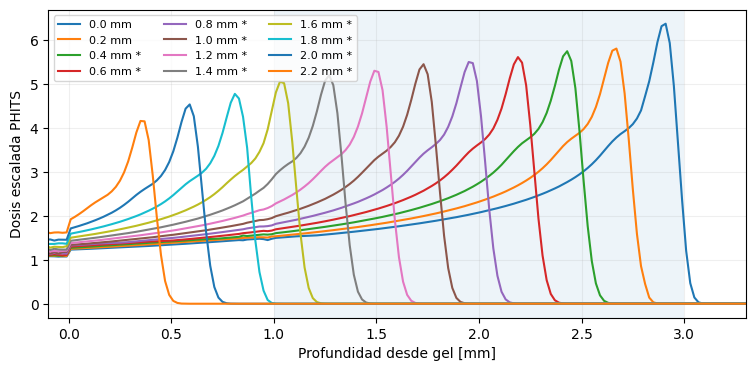

,t PLA mm,xBP mm,D pico,x distal 90 mm,historias
0,0.0,2.91,6.3798,2.934053,50000000
1,0.2,2.67,5.8139,2.697826,50000000
2,0.4,2.43,5.7531,2.461396,14440947
3,0.6,2.19,5.6190,2.226890,13975110
4,0.8,1.95,5.5076,1.992938,14596226
5,1.0,1.73,5.4573,1.760028,6366439
6,1.2,1.49,5.3078,1.532135,14285668
7,1.4,1.27,5.2071,1.299168,13819831
8,1.6,1.03,5.0599,1.070320,13819831
9,1.8,0.81,4.7814,0.847876,14285668


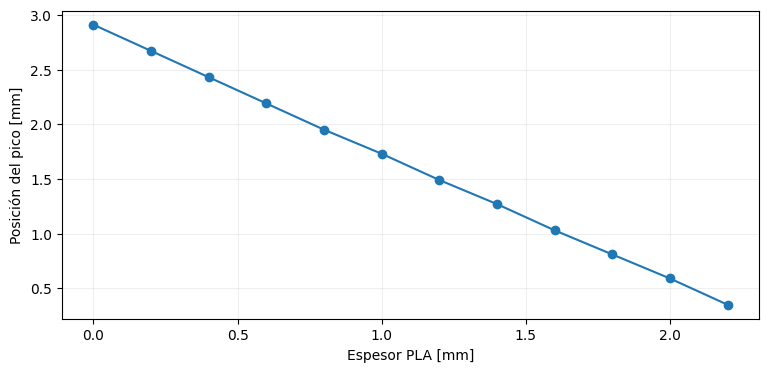

xBP = 2.8933 + (-1.1591) t [mm]
(*) Corrida parcial. Los valores son exploratorios.


,caso,t PLA mm,xBP mm,x proximal 50 mm,x distal 50 mm,FWHM mm,x proximal 90 mm,x distal 90 mm,ancho 90 mm,avisos
0,slab_t00,0.0,2.91,2.552771,2.977215,0.424444,2.860558,2.934053,0.073495,sin avisos
1,slab_t02,0.2,2.67,2.261931,2.744801,0.482870,2.615750,2.697826,0.082076,sin avisos
2,slab_t04,0.4,2.43,2.039608,2.508775,0.469168,2.381680,2.461396,0.079716,corrida parcial
3,slab_t06,0.6,2.19,1.810165,2.273628,0.463463,2.145753,2.226890,0.081138,corrida parcial
4,slab_t08,0.8,1.95,1.583084,2.038913,0.455829,1.911647,1.992938,0.081291,corrida parcial
5,slab_t10,1.0,1.73,1.370039,1.806433,0.436394,1.684473,1.760028,0.075555,corrida parcial
6,slab_t12,1.2,1.49,1.145092,1.575932,0.430840,1.454350,1.532135,0.077784,corrida parcial
7,slab_t14,1.4,1.27,0.938673,1.343942,0.405269,1.226067,1.299168,0.073101,ancho atraviesa interfaz; corrida parcial
8,slab_t16,1.6,1.03,0.718633,1.111631,0.392997,0.997563,1.070320,0.072757,ancho atraviesa interfaz; corrida parcial
9,slab_t18,1.8,0.81,0.487335,0.890665,0.403329,0.773660,0.847876,0.074216,corrida parcial


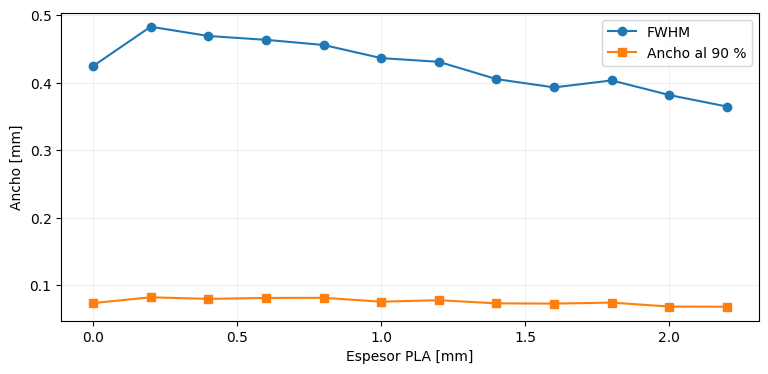

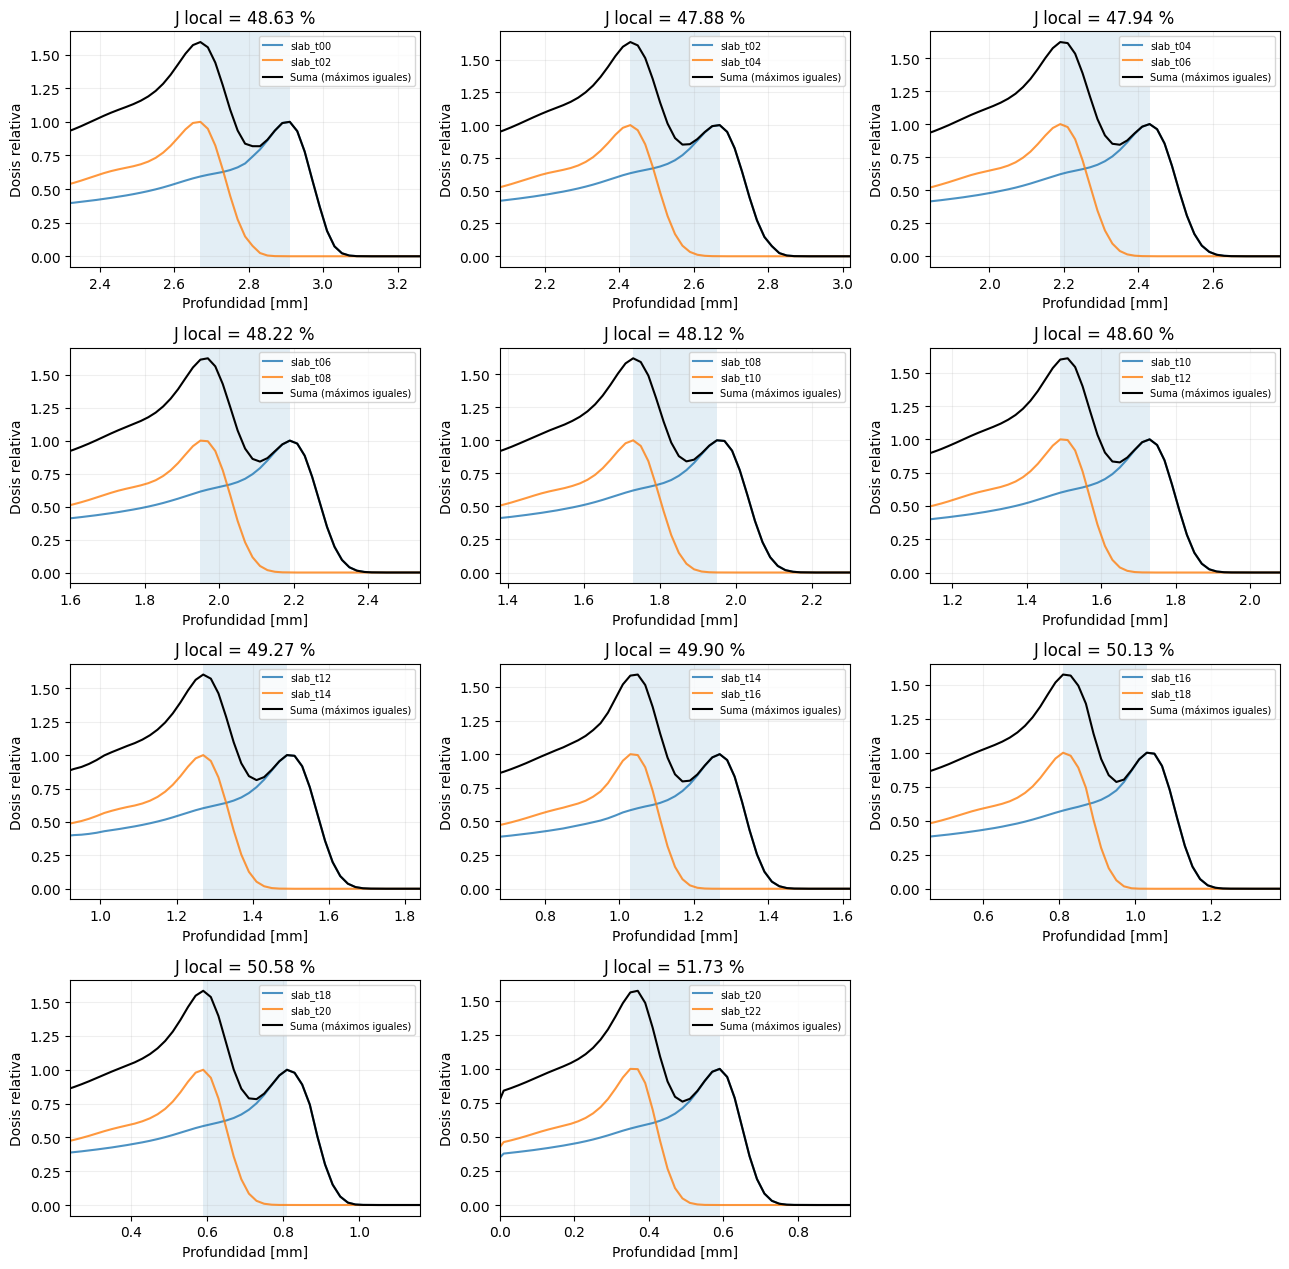

,slab 1,slab 2,t medio PLA mm,incremento PLA mm,separación mm,FWHM medio mm,separación/FWHM medio,mínimo suma relativa,máximo suma relativa,J local %,ambas completas
0,slab_t00,slab_t02,0.1,0.2,0.24,0.453657,0.529034,0.818712,1.593686,48.627798,True
1,slab_t02,slab_t04,0.3,0.2,0.24,0.476019,0.504182,0.851407,1.633516,47.878877,False
2,slab_t04,slab_t06,0.5,0.2,0.24,0.466316,0.514673,0.843764,1.620848,47.943036,False
3,slab_t06,slab_t08,0.7,0.2,0.24,0.459646,0.522141,0.841000,1.624237,48.221834,False
4,slab_t08,slab_t10,0.9,0.2,0.22,0.446111,0.493150,0.840831,1.620797,48.122370,False
5,slab_t10,slab_t12,1.1,0.2,0.24,0.433617,0.553484,0.827023,1.608879,48.596320,False
6,slab_t12,slab_t14,1.3,0.2,0.22,0.418055,0.526247,0.813124,1.602962,49.273667,False
7,slab_t14,slab_t16,1.5,0.2,0.24,0.399133,0.601303,0.797498,1.591711,49.896790,False
8,slab_t16,slab_t18,1.7,0.2,0.22,0.398163,0.552537,0.785341,1.574913,50.134284,False
9,slab_t18,slab_t20,1.9,0.2,0.22,0.392479,0.560540,0.782807,1.583971,50.579476,False


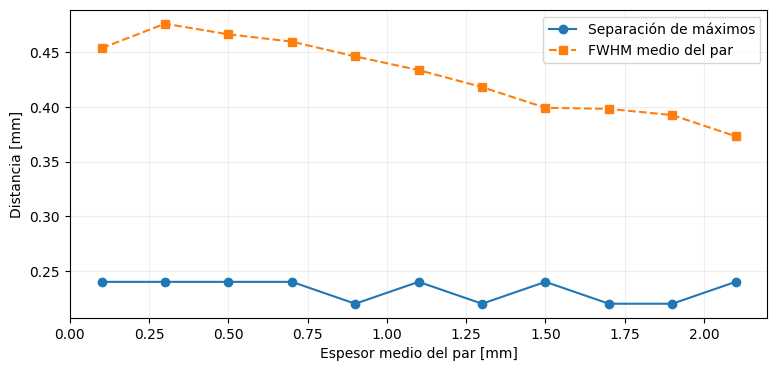

Diagnóstico de pares: máximos individuales igualados solo para comparar formas. La matriz A conserva la dosis original.


In [5]:
slabs = sorted(k for k in profiles if re.fullmatch(r'slab_t\d\d',k))
ts = np.array([int(k[-2:])/10 for k in slabs])
assert len(slabs)>0
x = profiles[slabs[0]][0]
assert all(np.allclose(profiles[k][0],x) for k in slabs)
A = np.column_stack([profiles[k][1] for k in slabs])
E = np.column_stack([profiles[k][2] for k in slabs])
medium = (x>=0)&(x<=3)

def distal(x,y,i,f=.9):
    for j in range(i,len(y)-1):
        level = f*y[i]
        if y[j]>=level>y[j+1]:
            return x[j]+(x[j+1]-x[j])*(y[j]-level)/(y[j]-y[j+1])
    return np.nan

fig,ax=plt.subplots()
peaks=[]
for k,t in zip(slabs,ts):
    xx,y,e,h=profiles[k]
    i=np.where(medium)[0][np.argmax(y[medium])]
    peaks.append([t,x[i],y[i],distal(x,y,i),h])
    ax.plot(x,y,label=f'{t:.1f} mm'+(' *' if not status[k] else ''))
ax.axvspan(1,3,alpha=.08); ax.set(xlim=(-.1,3.3),xlabel='Profundidad desde gel [mm]',ylabel='Dosis escalada PHITS'); ax.legend(ncol=3,fontsize=8); plt.show()
cal=pd.DataFrame(peaks,columns=['t PLA mm','xBP mm','D pico','x distal 90 mm','historias'])
display(cal)
plt.plot(cal['t PLA mm'],cal['xBP mm'],'o-'); plt.xlabel('Espesor PLA [mm]'); plt.ylabel('Posición del pico [mm]'); plt.show()
assert len(slabs)>=2, 'Se necesitan al menos dos slabs para ajustar'
fit=np.polyfit(cal['t PLA mm'],cal['xBP mm'],1)
print(f'xBP = {fit[1]:.4f} + ({fit[0]:.4f}) t [mm]')
print('(*) Corrida parcial. Los valores son exploratorios.')


def crossing_peak(x, y, i, fraction, side):
    if y[i] <= 0:
        return np.nan
    level = fraction*y[i]
    indices = range(i, 0, -1) if side == 'proximal' else range(i, len(y)-1)
    step = -1 if side == 'proximal' else 1
    for j in indices:
        k = j+step
        if y[j] >= level and y[k] < level:
            return x[j]+(x[k]-x[j])*(level-y[j])/(y[k]-y[j])
    return np.nan

width_rows = []
peak_indices = []
for k,t in zip(slabs,ts):
    xx,y,e,h = profiles[k]
    i = np.where(medium)[0][np.argmax(y[medium])]
    peak_indices.append(i)
    p50,d50,p90,d90 = [crossing_peak(xx,y,i,f,s) for f in (.5,.9) for s in ('proximal','distal')]
    crossings = np.array([p50,d50,p90,d90])
    notes = []
    if not np.isfinite(crossings).all():
        notes.append('cruce ausente')
    if np.any((crossings<0)|(crossings>3)):
        notes.append('cruce fuera de gel+pouch')
    if any(np.isfinite(p) and np.isfinite(d) and any(p<edge<d for edge in (0,.95,1,3)) for p,d in [(p50,d50),(p90,d90)]):
        notes.append('ancho atraviesa interfaz')
    if not status[k]:
        notes.append('corrida parcial')
    width_rows.append([k,t,xx[i],p50,d50,d50-p50,p90,d90,d90-p90,'; '.join(notes) or 'sin avisos'])
widths_peaks = pd.DataFrame(width_rows,columns=['caso','t PLA mm','xBP mm','x proximal 50 mm','x distal 50 mm','FWHM mm','x proximal 90 mm','x distal 90 mm','ancho 90 mm','avisos'])
display(widths_peaks)
fig,ax = plt.subplots()
ax.plot(ts,widths_peaks['FWHM mm'],'o-',label='FWHM')
ax.plot(ts,widths_peaks['ancho 90 mm'],'s-',label='Ancho al 90 %')
ax.set(xlabel='Espesor PLA [mm]',ylabel='Ancho [mm]'); ax.legend(); plt.show()

pair_rows = []
if len(slabs)>1:
    fig,axes = plt.subplots(int(np.ceil((len(slabs)-1)/3)),3,figsize=(13,3.2*int(np.ceil((len(slabs)-1)/3))),squeeze=False)
    for j,ax in enumerate(axes.flat):
        if j>=len(slabs)-1:
            ax.set_visible(False)
            continue
        i1,i2 = peak_indices[j:j+2]
        lo,hi = sorted((x[i1],x[i2]))
        delta = hi-lo
        fmean = np.mean(widths_peaks['FWHM mm'].iloc[j:j+2].to_numpy())
        ratio = delta/fmean if np.isfinite(fmean) and fmean>0 else np.nan
        win = (x>=lo)&(x<=hi)
        a,b = A[:,j],A[:,j+1]
        dmin=dmax=jpair=np.nan
        if a[i1]>0 and b[i2]>0:
            a,b = a/a[i1],b/b[i2]
            pair = a+b
            dmin,dmax = pair[win].min(),pair[win].max()
            jpair = 100*(1-dmin/dmax) if dmax>0 else np.nan
            ax.plot(x,a,label=slabs[j],alpha=.8)
            ax.plot(x,b,label=slabs[j+1],alpha=.8)
            ax.plot(x,pair,label='Suma (máximos iguales)',color='black')
            ax.axvspan(lo,hi,alpha=.12)
            ax.set(xlim=(lo-.35,hi+.35),xlabel='Profundidad [mm]',ylabel='Dosis relativa',title=f'J local = {jpair:.2f} %')
            ax.legend(fontsize=7)
        pair_rows.append([slabs[j],slabs[j+1],(ts[j]+ts[j+1])/2,ts[j+1]-ts[j],delta,fmean,ratio,dmin,dmax,jpair,status[slabs[j]] and status[slabs[j+1]]])
    fig.tight_layout(); plt.show()
pairs_peaks = pd.DataFrame(pair_rows,columns=['slab 1','slab 2','t medio PLA mm','incremento PLA mm','separación mm','FWHM medio mm','separación/FWHM medio','mínimo suma relativa','máximo suma relativa','J local %','ambas completas'])
display(pairs_peaks)
fig,ax = plt.subplots()
ax.plot(pairs_peaks['t medio PLA mm'],pairs_peaks['separación mm'],'o-',label='Separación de máximos')
ax.plot(pairs_peaks['t medio PLA mm'],pairs_peaks['FWHM medio mm'],'s--',label='FWHM medio del par')
ax.set(xlabel='Espesor medio del par [mm]',ylabel='Distancia [mm]'); ax.legend(); plt.show()
print('Diagnóstico de pares: máximos individuales igualados solo para comparar formas. La matriz A conserva la dosis original.')


## 3. Optimización de pesos
En vez de minimizar el CV o elegir una dosis objetivo arbitraria, se maximiza m = Dmin/Dmax mediante programación lineal: variables u proporcionales a los pesos, Au ≤ 1 y Au ≥ m; después w = u/sum(u). Esto minimiza J = 100(1 − Dmin/Dmax) para la ventana discreta, antes del redondeo. Se impone u_i ≥ (ancho mínimo/período) sum(u). La solución redondeada es una aproximación, no el óptimo discreto global.

La resolución por lado de 25 µm es **una hipótesis**; se utiliza un incremento conservador de 50 µm en el ancho completo para que los semianchos sean múltiplos de 25 µm. El escalón central podría permitir un tratamiento diferente. El espesor vertical y los anchos mínimos reales deben medirse con la resina y la impresora. `ALLOW_PARTIAL=True` permite explorar salidas parciales; cambiar a False para exigir toda la base completa. Los resultados sin restricción física son una cota idealizada.

Se incluyen tres variantes: mínimos cuadrados original de Sara (cota previa a normalizar), mínimos cuadrados con cota física sobre el peso final y programación lineal. Las últimas dos se comparan sobre idénticos bins, límites y redondeo. La variante original se conserva como referencia; su cota previa a normalizar no garantiza un ancho mínimo final. La comparación de mínimos cuadrados corregidos usa la misma función objetivo que Sara en variables auxiliares, con escala común para mejorar el condicionamiento numérico.

In [6]:
ALLOW_PARTIAL = True
MIN_WIDTH = RES
assert len(slabs)>=3, 'Faltan slabs para una optimización exploratoria'
assert np.allclose(ts,np.arange(len(ts))*.2), 'Faltan espesores consecutivos'
assert np.isclose(ts[-1],2.2), 'La base original requiere t00 a t22'
if not ALLOW_PARTIAL:
    assert all(status[k] for k in slabs), 'Completar todas las simulaciones de slabs'
else:
    print('ANÁLISIS EXPLORATORIO:', sum(status[k] for k in slabs), 'de', len(slabs), 'slabs completos')

def optimize(a, lower=0):
    m,p=a.shape
    scale=np.max(a)
    if scale<=0: raise ValueError('Ventana sin dosis')
    B=a/scale
    C=np.vstack([np.column_stack([B,np.zeros(m)]),np.column_stack([-B,np.ones(m)]),np.column_stack([lower*np.ones((p,p))-np.eye(p),np.zeros(p)])])
    rhs=np.r_[np.ones(m),np.zeros(m),np.zeros(p)]
    sol=linprog(np.r_[np.zeros(p),-1],A_ub=C,b_ub=rhs,bounds=[(0,None)]*p+[(0,1)],method='highs',options={'primal_feasibility_tolerance':1e-9,'dual_feasibility_tolerance':1e-9})
    if not sol.success or sol.x[:-1].sum()<=0: return None
    mstar=sol.x[-1]
    if mstar<=1e-10: return None
    second=linprog(np.r_[np.ones(p),0],A_ub=C,b_ub=rhs,bounds=[(0,None)]*p+[(max(0,mstar-1e-8),mstar)],method='highs',options={'primal_feasibility_tolerance':1e-9,'dual_feasibility_tolerance':1e-9})
    u=second.x[:-1] if second.success else sol.x[:-1]
    w=u/u.sum()
    assert np.isclose(w.sum(),1) and np.min(w)>=lower-1e-7
    return w,scale/u.sum(),1-sol.x[-1]

def optimize_ls(a, lower=0, original=False):
    scale=np.max(a)
    if scale<=0: return None
    p=a.shape[1]
    if original:
        sol=lsq_linear(a,np.ones(a.shape[0]),bounds=(np.full(p,lower),np.inf),tol=1e-12)
        if not sol.success: return None
        u=sol.x
        ref=1/u.sum()
    else:
        B=a/scale
        C=np.eye(p)-lower*np.ones((p,p))
        fun=lambda u: .5*np.mean((B@u-1)**2)
        jac=lambda u: B.T@(B@u-1)/len(B)
        u0=np.ones(p)/p
        u0=u0/max(np.mean(B@u0),1e-12)
        sol=minimize(fun,u0,jac=jac,bounds=[(0,None)]*p,constraints=[{'type':'ineq','fun':lambda u:C@u,'jac':lambda u:C}],method='SLSQP',options={'ftol':1e-12,'maxiter':500})
        if not sol.success or np.min(C@sol.x)<-1e-7: return None
        u=sol.x
        ref=scale/u.sum()
    if u.sum()<=0: return None
    w=u/u.sum()
    y=a@w
    return w,ref,1-y.min()/y.max()

METHODS={'MC Sara':lambda a,l:optimize_ls(a,l,True),'MC con cota física':optimize_ls,'Programación lineal':optimize}

def quantize(w,period=PERIODO,res=RES,min_width=MIN_WIDTH):
    K=round(period/res)
    if not np.isclose(K*res,period): raise ValueError('Período no divisible por resolución de ancho completo')
    low=int(np.ceil(min_width/res-1e-10)); q=np.maximum(low,np.floor(w*K).astype(int))
    if low*len(w)>K: raise ValueError('Anchos mínimos incompatibles')
    while q.sum()<K: q[np.argmax(w*K-q)]+=1
    while q.sum()>K:
        idx=np.where(q>low)[0]; q[idx[np.argmax(q[idx]-w[idx]*K)]]-=1
    assert q.sum()==K and np.all(q>=low)
    return q/K

def evaluate(w,l,r,ref):
    win=(x>=l-1e-9)&(x<=r+1e-9); y=A@w
    m,cv,mi,ma=metrics(y[win])
    err=np.sum(E*A*w,axis=1)
    mid=(np.max(y[win])+np.min(y[win]))/2
    return [l,r,r-l,m,cv,mi,ma,100*np.max(np.abs(y[win]/mid-1)) if mid>0 else np.nan,100*np.max(err[win]/m) if m>0 else np.nan]

results=[]; candidates={}
for length in [.5,.75,1.,1.25,1.5,2.,2.25,2.5,2.75,3.]:
    for l in np.arange(0,3-length+1e-8,.05):
        r=l+length; win=(x>=l-1e-9)&(x<=r+1e-9)
        for lower in [0,MIN_WIDTH/PERIODO]:
            for method,solver in METHODS.items():
                sol=solver(A[win],lower)
                if sol is None: continue
                w,ref,eps=sol
                wr=quantize(w) if lower else w
                key=len(results); candidates[key]=(w,wr,ref)
                results.append([key,method,bool(lower),np.min(w)*PERIODO>=MIN_WIDTH-1e-8 if lower else True,*evaluate(wr,l,r,ref)])
cols=['id','método','ancho mínimo y redondeo','cota continua válida','inicio mm','fin mm','ancho mm','media','CV %','min/media %','max/media %','desv máx ref %','cota estadística aprox %']
scan=pd.DataFrame(results,columns=cols)
scan['ancho mm']=scan['ancho mm'].round(4)
scan['J Mariel %']=100*(1-scan['min/media %']/scan['max/media %'])
scan['J < 5%']=scan['J Mariel %']<5
summary=scan.sort_values('J Mariel %').groupby(['método','ancho mm','ancho mínimo y redondeo'],as_index=False).first()
display(summary.round(3))
print('Las mejores ventanas por método pueden ser distintas; la comparación fija siguiente evita ese efecto.')
print('La búsqueda usa ventanas discretas y centros de bins, no anchos SOBP al 90 %.')


ANÁLISIS EXPLORATORIO: 2 de 12 slabs completos


,método,ancho mm,ancho mínimo y redondeo,id,cota continua válida,inicio mm,fin mm,media,CV %,min/media %,max/media %,desv máx ref %,cota estadística aprox %,J Mariel %,J < 5%
0,MC Sara,0.50,False,60,True,0.50,1.00,0.897,0.944,98.239,101.415,1.591,0.139,3.132,True
1,MC Sara,0.50,True,57,True,0.45,0.95,1.368,1.323,97.943,101.918,1.989,0.119,3.900,True
2,MC Sara,0.75,False,342,True,0.30,1.05,1.435,1.246,97.664,102.011,2.177,0.098,4.261,True
3,MC Sara,0.75,True,345,True,0.30,1.05,1.460,1.646,97.262,103.119,2.923,0.111,5.679,False
4,MC Sara,1.00,False,618,True,0.30,1.30,1.426,1.425,96.687,102.336,2.838,0.102,5.520,False
5,MC Sara,1.00,True,621,True,0.30,1.30,1.457,1.705,97.060,102.860,2.901,0.113,5.638,False
6,MC Sara,1.25,False,876,True,0.40,1.65,1.464,1.795,96.400,102.684,3.156,0.117,6.120,False
7,MC Sara,1.25,True,885,True,0.45,1.70,1.413,1.995,96.881,103.856,3.475,0.136,6.717,False
8,MC Sara,1.50,False,1086,True,0.35,1.85,1.504,2.015,96.300,103.072,3.397,0.119,6.570,False
9,MC Sara,1.50,True,1083,True,0.30,1.80,1.504,2.076,96.268,103.269,3.508,0.124,6.779,False


Las mejores ventanas por método pueden ser distintas; la comparación fija siguiente evita ese efecto.
La búsqueda usa ventanas discretas y centros de bins, no anchos SOBP al 90 %.


## 4. Comparación de ambos métodos en ventanas idénticas
Se comparan las tres variantes en la ventana original de Sara, el pouch real y el objetivo de 3 mm. Se muestran resultados continuos y con el mismo redondeo conservador. La dosis no se normaliza por separado en los gráficos. Los pesos son exploratorios si faltan historias.

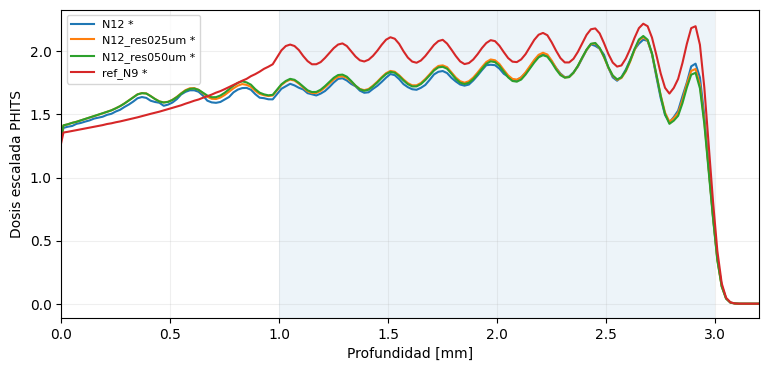

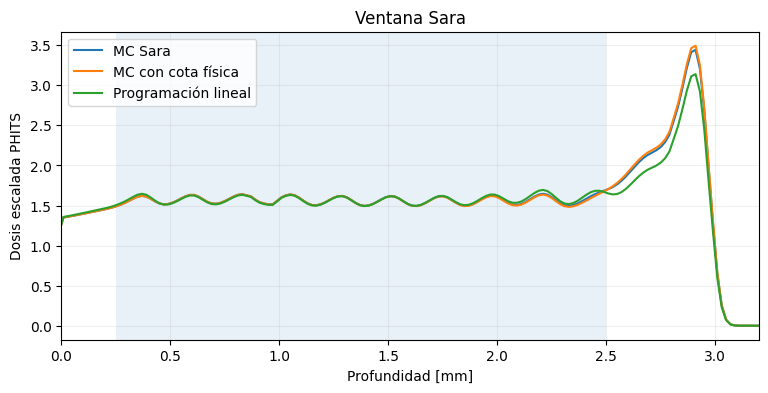

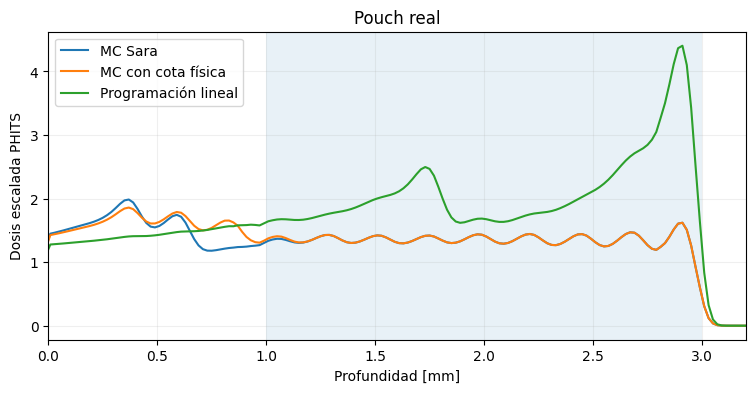

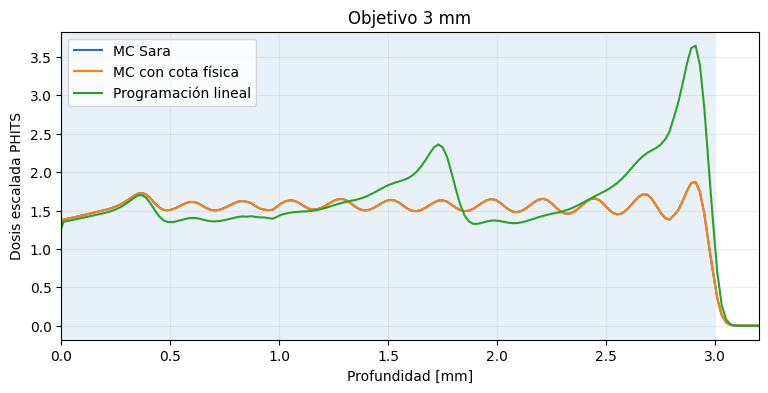

,ventana,método,modo,media,CV %,J Mariel %,mín/media %,cota válida,candidato numérico
0,Ventana Sara,MC Sara,Continuo,1.5677,2.9800,11.6130,94.9992,True,False
1,Ventana Sara,MC Sara,Redondeado común,1.5671,3.0385,11.6272,94.9861,True,False
2,Ventana Sara,MC con cota física,Continuo,1.5656,2.9646,11.9183,95.0134,True,False
3,Ventana Sara,MC con cota física,Redondeado común,1.5631,3.0334,11.5924,94.8205,True,False
4,Ventana Sara,Programación lineal,Continuo,1.5729,3.1493,9.9252,95.7299,True,False
5,Ventana Sara,Programación lineal,Redondeado común,1.5740,3.2897,11.9306,94.8114,True,False
6,Pouch real,MC Sara,Continuo,1.3331,8.3052,62.8174,45.1604,True,False
7,Pouch real,MC Sara,Redondeado común,1.3490,8.3294,62.8174,44.6605,True,False
8,Pouch real,MC con cota física,Continuo,1.3397,8.3052,62.8174,45.1603,True,False
9,Pouch real,MC con cota física,Redondeado común,1.3513,8.3374,62.8174,44.5850,True,False


método              MC Sara                  MC con cota física  \
modo               Continuo Redondeado común           Continuo   
ventana       t mm                                                
Objetivo 3 mm 0.0   0.29585          0.29365            0.29585   
              0.2   0.09916          0.10317            0.09916   
              0.4   0.08313          0.07937            0.08313   
              0.6   0.07034          0.07143            0.07034   
              0.8   0.06240          0.06349            0.06240   
              1.0   0.05690          0.05556            0.05690   
              1.2   0.05423          0.05556            0.05424   
              1.4   0.05237          0.05556            0.05237   
              1.6   0.04971          0.04762            0.04971   
              1.8   0.04921          0.04762            0.04921   
              2.0   0.05119          0.04762            0.05119   
              2.2   0.07550          0.07937            0.07550   
Pouch real    0.0   0.25379          0.25397            0.25505   
              0.2   0.08505          0.08730            0.08548   
              0.4   0.07130          0.07143            0.07165   
              0.6   0.06026          0.06349            0.06056   
              0.8   0.05335          0.05556            0.05361   
              1.0   0.04875          0.04762            0.04899   
              1.2   0.04629          0.04762            0.04653   
              1.4   0.04491          0.04762            0.04514   
              1.6   0.03588          0.03175            0.03603   
              1.8   0.01065          0.00794            0.09898   
              2.0   0.14489          0.14286            0.09899   
              2.2   0.14489          0.14286            0.09899   
Ventana Sara  0.0   0.53850          0.53968            0.55179   
              0.2   0.01245          0.00794            0.00794   
              0.4   0.01245          0.01587            0.00794   
              0.6   0.05459          0.05556            0.05358   
              0.8   0.05052          0.04762            0.04974   
              1.0   0.04916          0.04762            0.04862   
              1.2   0.04829          0.04762            0.04787   
              1.4   0.04740          0.04762            0.04704   
              1.6   0.04439          0.04762            0.04402   
              1.8   0.04448          0.04762            0.04418   
              2.0   0.04813          0.04762            0.04789   
              2.2   0.04963          0.04762            0.04939   

método                              Programación lineal                   
modo               Redondeado común            Continuo Redondeado común  
ventana       t mm                                                        
Objetivo 3 mm 0.0           0.29365             0.56990          0.57143  
              0.2           0.10317             0.00794          0.00794  
              0.4           0.07937             0.00794          0.00794  
              0.6           0.07143             0.01185          0.00794  
              0.8           0.06349             0.02751          0.02381  
              1.0           0.05556             0.21190          0.21429  
              1.2           0.05556             0.00794          0.00794  
              1.4           0.05556             0.00794          0.00794  
              1.6           0.04762             0.00794          0.00794  
              1.8           0.04762             0.01197          0.01587  
              2.0           0.04762             0.02595          0.02381  
              2.2           0.07937             0.10124          0.10317  
Pouch real    0.0           0.25397             0.68930          0.69048  
              0.2           0.08730             0.00794          0.00794  
              0.4           0.07143             0.00794          0.00794  
              0.6           0.06349 

Candidato numérico no significa aprobado para fabricar: requiere validación 3D y experimental.


In [7]:
fig,ax=plt.subplots()
for k in profiles:
    if not k.startswith('slab'):
        xx,y,e,h=profiles[k]; ax.plot(xx,y,label=k+(' *' if not status[k] else ''))
ax.axvspan(1,3,alpha=.08); ax.set(xlim=(0,3.2),xlabel='Profundidad [mm]',ylabel='Dosis escalada PHITS'); ax.legend(fontsize=8); plt.show()
fixed=[]; weight_rows=[]
for label,l,r in [('Ventana Sara',.25,2.5),('Pouch real',GEL,GEL+POUCH),('Objetivo 3 mm',0,3)]:
    win=(x>=l-1e-9)&(x<=r+1e-9)
    fig,ax=plt.subplots()
    for method,solver in METHODS.items():
        sol=solver(A[win],MIN_WIDTH/PERIODO)
        if sol is None:
            print('Sin solución:',label,method); continue
        w,ref,eps=sol; wr=quantize(w)
        for mode,v in [('Continuo',w),('Redondeado común',wr)]:
            y=A@v; m,cv,mi,ma=metrics(y[win]); J=100*(1-mi/ma)
            valid=np.min(v)*PERIODO>=MIN_WIDTH-1e-8
            fixed.append([label,method,mode,m,cv,J,mi,valid,J<5 and valid and all(status[k] for k in slabs)])
            for t,weight in zip(ts,v): weight_rows.append([label,method,mode,t,weight,weight*PERIODO])
            if mode=='Redondeado común': ax.plot(x,y,label=method)
    ax.axvspan(l,r,alpha=.1); ax.set(xlim=(0,3.2),xlabel='Profundidad [mm]',ylabel='Dosis escalada PHITS',title=label); ax.legend(); plt.show()
fixed_comparison=pd.DataFrame(fixed,columns=['ventana','método','modo','media','CV %','J Mariel %','mín/media %','cota válida','candidato numérico'])
weights_comparison=pd.DataFrame(weight_rows,columns=['ventana','método','modo','t mm','peso','ancho completo mm'])
display(fixed_comparison.round(4))
display(weights_comparison.pivot(index=['ventana','t mm'],columns=['método','modo'],values='peso').round(5))
print('Candidato numérico no significa aprobado para fabricar: requiere validación 3D y experimental.')


### 4b. Verificar la aproximación de área con las geometrías existentes
Compara el resultado PHITS real y la mezcla de slabs con los mismos anchos nominales y sin renormalizar. Un desacuerdo puede deberse a iluminación no uniforme, dispersión y trayectorias que cruzan escalones, o diferencias de configuración. Los perfiles parciales son orientativos. J = 100(1 - Dmin/Dmax) es el criterio longitudinal de Mariel; no confundir con CV ni con desviación respecto a la dosis de referencia.

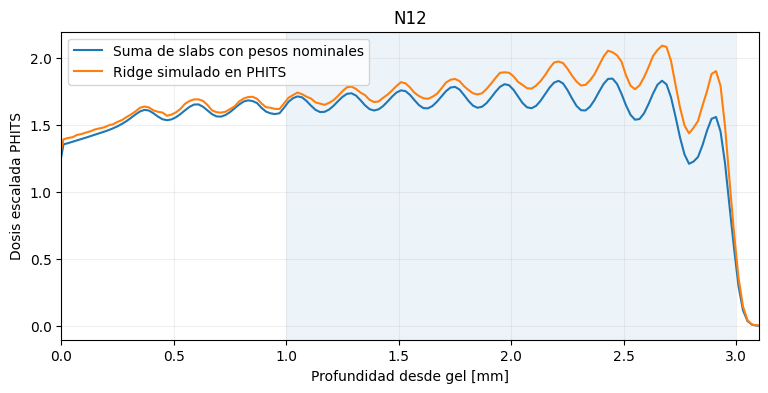

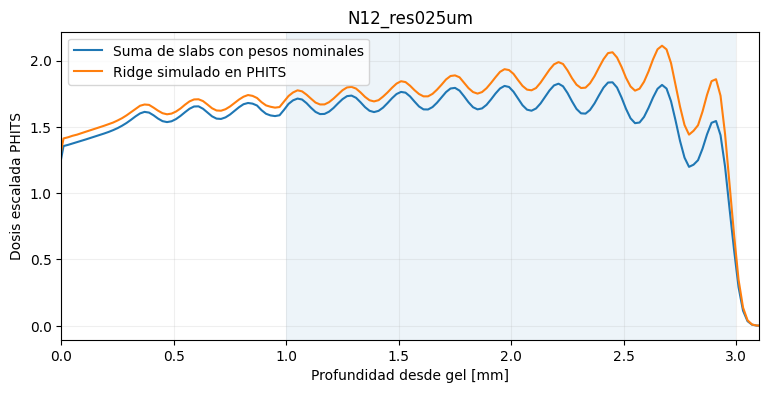

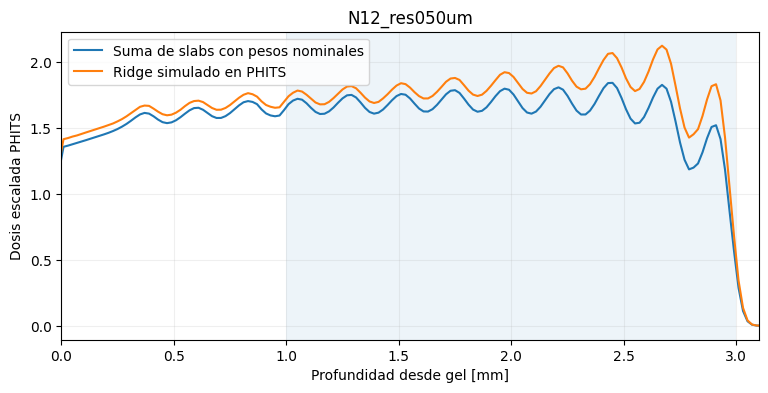

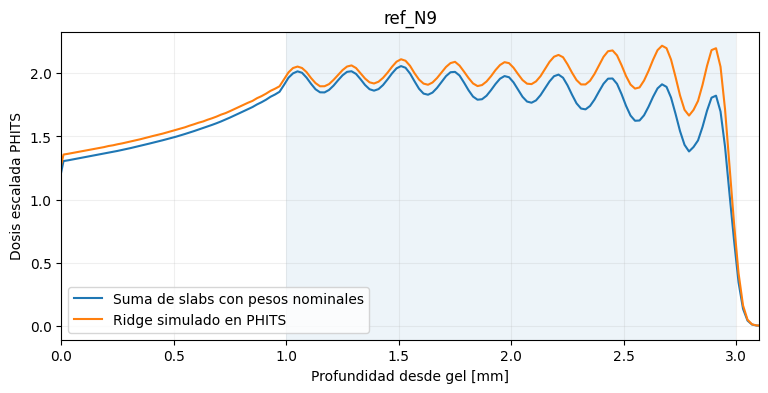

,caso,tipo,inicio mm,fin mm,media,CV %,mín/media %,máx/media %,J Mariel %
0,N12,Ridge PHITS,0.5,2.5,1.761,6.143,90.390,116.680,22.532
1,N12,Suma slabs,0.5,2.5,1.680,4.226,92.764,109.926,15.612
2,N12,Ridge PHITS,1.0,3.0,1.777,10.237,38.926,117.696,66.926
3,N12,Suma slabs,1.0,3.0,1.640,11.347,35.364,112.595,68.591
4,N12,Ridge PHITS,0.0,3.0,1.713,10.590,40.385,122.105,66.926
5,N12,Suma slabs,0.0,3.0,1.610,10.299,36.007,114.641,68.591
6,N12_res025um,Ridge PHITS,0.5,2.5,1.784,5.823,90.602,115.668,21.671
7,N12_res025um,Suma slabs,0.5,2.5,1.680,4.226,92.805,109.320,15.107
8,N12_res025um,Ridge PHITS,1.0,3.0,1.792,10.286,38.476,117.897,67.365
9,N12_res025um,Suma slabs,1.0,3.0,1.637,11.522,35.071,112.167,68.733


In [8]:
nominal = {}
for k in profiles:
    if k.startswith('slab'): continue
    folder=CASOS/k
    if k=='ref_N9':
        widths=np.array([.04,.04,.05,.05,.05,.06,.07,.09,.18])
    else:
        txt=next(folder.glob('ridge_*.txt')).read_text().split('espesor 0):')[-1]
        vals=re.findall(r'float64\(([0-9.]+)\)',txt)
        if not vals: vals=re.findall(r'[0-9]+\.[0-9]+',txt)
        widths=np.array([float(v) for v in vals])
    if len(widths)>len(ts): continue
    w=np.pad(widths[::-1]/widths.sum(),(0,len(ts)-len(widths)))
    nominal[k]=w
rows=[]
for k,w in nominal.items():
    xx,y,e,h=profiles[k]; pred=A@w
    if not np.allclose(xx,x): raise ValueError(f'Malla incompatible: {k}')
    fig,ax=plt.subplots()
    ax.plot(x,pred,label='Suma de slabs con pesos nominales')
    ax.plot(xx,y,label='Ridge simulado en PHITS')
    ax.axvspan(1,3,alpha=.08); ax.set(xlim=(0,3.1),xlabel='Profundidad desde gel [mm]',ylabel='Dosis escalada PHITS',title=k); ax.legend(); plt.show()
    for l,r in [(0.5,2.5),(1,3),(0,3)]:
        s=(x>=l)&(x<=r)
        for mode,v in [('Ridge PHITS',y),('Suma slabs',pred)]:
            m,cv,mi,ma=metrics(v[s]); rows.append([k,mode,l,r,m,cv,mi,ma,100*(1-mi/ma)])
compare=pd.DataFrame(rows,columns=['caso','tipo','inicio mm','fin mm','media','CV %','mín/media %','máx/media %','J Mariel %'])
display(compare.round(3))

## 5. Anillos y espectros
Anillos: r=0–0,4 y 0,4–0,8 cm; no cubren todo el pouch y el promedio azimutal oculta ondulaciones. La región espectral de entrada es cuadrada de 1 cm × 1 cm, no idéntica al disco central de dosis. El T-Track fino mide fluencia dentro de una lámina, no corriente superficial. Integrar por ancho del bin porque `unit=2` expresa fluencia por MeV. La distribución acumulada es ponderada por fluencia, no por número de protones primarios. Los espectros de distintas geometrías requieren comparar tanto la fluencia absoluta como su forma.

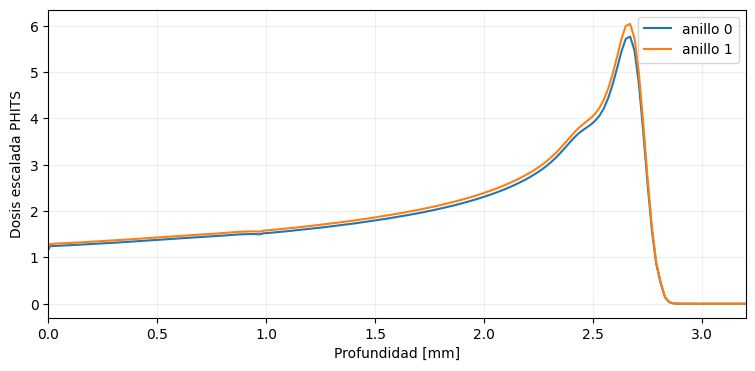

slab_t00 fluencia integrada: 249256201.51
slab_t02 fluencia integrada: 243179173.23400003
ref_N9 fluencia integrada: 237329360.68199998
N12 fluencia integrada: 209553397.953


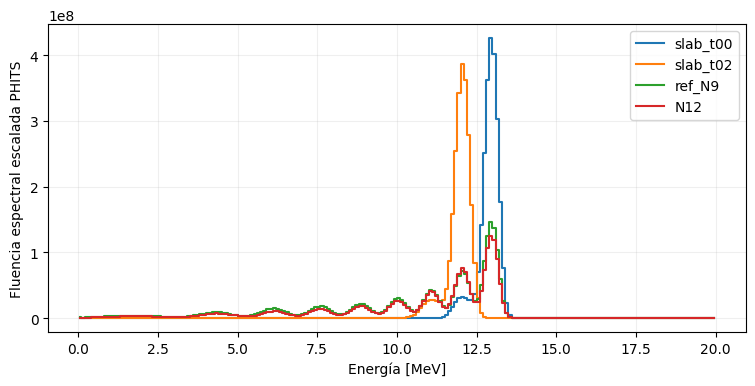

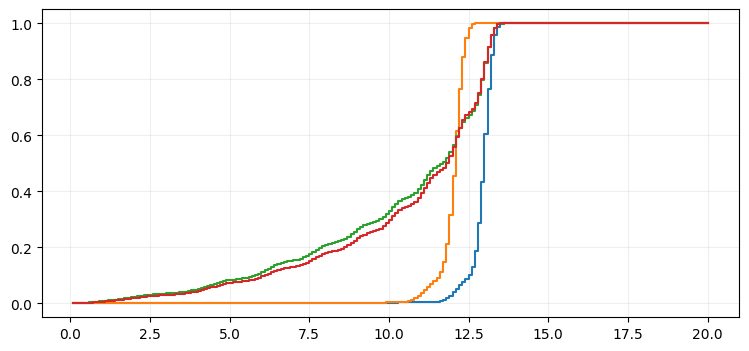

In [9]:
CASE='slab_t02'
folder=CASOS/CASE
fig,ax=plt.subplots()
for block in [0,1]:
    try:
        xx,y,e,h=profile(folder,block); ax.plot(xx,y,label=f'anillo {block}'); ax.fill_between(xx,y*(1-e),y*(1+e),alpha=.12)
    except (OSError,ValueError,IndexError) as exc: print(exc)
ax.set(xlim=(0,3.2),xlabel='Profundidad [mm]',ylabel='Dosis escalada PHITS'); ax.legend(); plt.show()
fig,ax=plt.subplots()
fig_cdf,ax_cdf=plt.subplots()
for k in ['slab_t00','slab_t02','ref_N9','N12']:
    try:
        a,h=read_tally(CASOS/k/'out'/'espectro_entrada_pouch.out',axis='e',expected=200)
        ax.step(a[:,:2].mean(1),a[:,2],where='mid',label=k)
        phi=a[:,2]*(a[:,1]-a[:,0])
        print(k,'fluencia integrada:',phi.sum())
        if phi.sum()>0: ax_cdf.step(a[:,1],np.cumsum(phi)/phi.sum(),where='post',label=k)
    except (OSError,ValueError,IndexError) as exc: print(k,exc)
ax.set(xlabel='Energía [MeV]',ylabel='Fluencia espectral escalada PHITS'); ax.legend(); plt.show()
ax_cdf.set(xlabel='Energía [MeV]',ylabel='Fracción acumulada de fluencia',ylim=(0,1.02)); ax_cdf.legend(); plt.show()

## 6. Antes de generar un filtro
- Completar las historias y revisar errores de geometría; comprobar que los archivos correspondan a sus inputs y que no haya reinicios o normalizaciones incompatibles.
- Confirmar asignación de material: celda 510 usa mat[16] skin; el cuerpo usa %skin% = mat[18], anotado como soft tissue (pouch). No cambiar sin consultar al equipo.
- El objetivo ≥3 mm requiere caracterizar alcance y ancho de modulación en un fantoma homogéneo suficientemente largo, y confirmar cobertura en el montaje real. No usar el cruce distal al 90 % del pico individual como límite matemático del SOBP.
- Verificar propiedades y resolución de la resina real, repetir la base si cambia material o geometría, simular el filtro completo y evaluar dosis total, mapas XY, DVH, LET, robustez y validación experimental supervisada.
- Este notebook reúne el análisis central; no sustituye gen_ridge.py, check_exact.py, check_geom.py ni una validación de transporte PHITS.